# Colab runner — RoBERTa seeds 2 and 3 (partitions 78516, 944601)

The first RoBERTa sweep covered only partition `5768`. The TF-IDF baseline used all three,
so this notebook runs the other two for RoBERTa (pooled + size control + all 25 LOBO folds
each) to put both models on equal footing and give the per-bank gaps real error bars.

**Runtime → Change runtime type → T4 GPU** before you start.

### Resuming
Results go to **Google Drive**, one JSON per fold. After any disconnect: reconnect, re-run
**Stages 0–3**, then re-run the sweep cell you were on. Finished folds are skipped, so a
disconnect costs at most one fold (~7 min).

### Budget
Each seed is 27 folds (1 pooled + 1 size control + 25 LOBO) at ~7 min ≈ **3.2 h per seed**,
~6.5 h for both. That is more than one free-tier session, so expect to reconnect once or
twice. The sweep is ordered so that seed 78516 is complete before 944601 starts.

Hyperparameters are **not** re-searched: `selected_hparams.json` from the first run is
reused (lr 1e-5, batch 32), so all three partitions share one model-selection budget.

## Stage 0 — confirm you have a GPU

In [ ]:
!nvidia-smi
import torch
print("torch", torch.__version__, "| cuda available:", torch.cuda.is_available())
assert torch.cuda.is_available(), "No GPU. Runtime > Change runtime type > T4 GPU"
print("device:", torch.cuda.get_device_name(0))

Fri Nov 13 14:38:06 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   40C    P8              9W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

## Stage 1 — mount Drive (same folder as the first run)

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import os, pathlib
DRIVE_ROOT = '/content/drive/MyDrive/cs72_final_project'
os.environ['WCB_RESULTS_DIR'] = f'{DRIVE_ROOT}/results'
os.environ['WCB_FIGURES_DIR'] = f'{DRIVE_ROOT}/figures'
for p in (os.environ['WCB_RESULTS_DIR'], os.environ['WCB_FIGURES_DIR']):
    pathlib.Path(p).mkdir(parents=True, exist_ok=True)
print('results ->', os.environ['WCB_RESULTS_DIR'])

hp = pathlib.Path(os.environ['WCB_RESULTS_DIR'], 'roberta', 'selected_hparams.json')
assert hp.exists(), f"{hp} missing - the first RoBERTa run's results must be in this Drive folder"
print(hp.read_text()[:120])

Mounted at /content/drive
results -> /content/drive/MyDrive/cs72_final_project/results
{
  "best": {
    "batch_size": 32,
    "learning_rate": 1e-05
  },
  "all": [
    {
      "batch_size": 32,
      "lear


## Stage 2 — get the code onto Colab

Same as the first run: unzip `final_project.zip` from the Drive folder. (If you have not
changed any code since, the existing zip is fine.)

In [ ]:
!rm -rf /content/final_project
!unzip -q {DRIVE_ROOT}/final_project.zip -d /content/
import os; os.chdir('/content/final_project')
!ls

'CS 72 Project Proposal.pdf'   pyproject.toml	  results
 figures		       README.md	  scripts
 notebooks		       requirements.txt   src


## Stage 3 — install dependencies

Do **not** install torch (it would replace Colab's CUDA-matched build).

In [ ]:
!pip install -q datasets transformers nltk
!pip install -q -e . --no-deps
import nltk; nltk.download('punkt_tab', quiet=True)

import sys, os, pathlib
# A running kernel cannot see a package pip installed moments ago, and restarting would
# drop the Drive mount, so add src/ to sys.path directly.
root = next((p for p in ('/content/final_project', '/content/final_project/final_project')
             if pathlib.Path(p, 'src', 'wcb', 'config.py').exists()), None)
assert root, "couldn't find src/wcb - check Stage 2 actually unzipped"
os.chdir(root)
if f'{root}/src' not in sys.path:
    sys.path.insert(0, f'{root}/src')

from wcb import config as C
print('project :', root)
print('results :', C.RESULTS_DIR)
assert str(C.RESULTS_DIR).startswith('/content/drive'), 'results are NOT on Drive - re-run Stage 1'
print('\nOK')

  Installing build dependencies ... done
  Checking if build backend supports build_editable ... done
  Getting requirements to build editable ... done
  Preparing editable metadata (pyproject.toml) ... done
  Building editable for wcb-transfer (pyproject.toml) ... done
project : /content/final_project
results : /content/drive/MyDrive/cs72_final_project/results

OK


## Stage 4 — how much is already done?

Safe to run at any time, including right after a disconnect.

In [ ]:
import glob, os
SEEDS = [5768, 78516, 944601]
print(f"{'seed':<8}{'pooled':>8}{'size_ctl':>10}{'lobo':>8}")
for s in SEEDS:
    n = {c: len(glob.glob(f"{C.RESULTS_DIR}/roberta/seed{s}/{c}/*.json"))
         for c in ('pooled', 'size_control', 'lobo')}
    print(f"{s:<8}{n['pooled']:>5}/25{n['size_control']:>7}/25{n['lobo']:>5}/25")

seed      pooled  size_ctl    lobo
5768       25/25     25/25   25/25
78516      25/25     25/25   25/25
944601     25/25     25/25   18/25


## Stage 5 — the sweep

Run **in order**. Every cell is resumable, so after a disconnect just re-run the one you
were on. `--no-save-pooled` skips the ~500 MB pooled checkpoint for these seeds: the demo
and the Czech check already use the seed-5768 one.

| cell | folds | time | what you have afterwards |
|---|---|---|---|
| 5a | 2 | ~15 min | seed 78516 ceiling + size control |
| 5b | 25 | ~3 h | seed 78516 complete |
| 5c | 2 | ~15 min | seed 944601 ceiling + size control |
| 5d | 25 | ~3 h | seed 944601 complete |

In [ ]:
# 5a - seed 78516: pooled + size control
!python scripts/run_roberta.py --seeds 78516 --condition pooled size_control --no-save-pooled

device: cuda
using frozen hyperparameters from selected_hparams.json: {'batch_size': 32, 'learning_rate': 1e-05}

=== seed 78516 ===
README.md: 100% 4.50k/4.50k [00:00<00:00, 10.1MB/s]

78516/train-00000-of-00001.parquet: downloading bytes:  34% 629k/1.88M [00:01<00:02, 611kB/s, 5.06kB/s  ]
78516/train-00000-of-00001.parquet: downloading bytes: 100% 1.86M/1.86M [00:01<00:00, 1.21MB/s,  178kB/s  ]
78516/train-00000-of-00001.parquet: reconstructing file: 100% 1.88M/1.88M [00:01<00:00, 1.22MB/s,  180kB/s  ]

78516/test-00000-of-00001.parquet: downloading bytes:  29% 120k/406k [00:00<00:02, 130kB/s]
78516/test-00000-of-00001.parquet: downloading bytes: 100% 402k/402k [00:01<00:00, 393kB/s, 38.9kB/s  ]
78516/test-00000-of-00001.parquet: reconstructing file: 100% 406k/406k [00:01<00:00, 397kB/s, 39.3kB/s  ]

78516/val-00000-of-00001.parquet: downloading bytes:  11% 45.5k/402k [00:00<00:07, 49.3kB/s]
78516/val-00000-of-00001.parquet: downloading bytes: 100% 398k/398k [00:01<00:00, 378kB/s, 38

In [ ]:
# 5b - seed 78516: all 25 LOBO folds. Re-run after any disconnect.
!python scripts/run_roberta.py --seeds 78516 --condition lobo

device: cuda
using frozen hyperparameters from selected_hparams.json: {'batch_size': 32, 'learning_rate': 1e-05}

=== seed 78516 ===
dedup: train 17500->17468 (-32), val 3750->3749 (-1), test 3750 (untouched)
lobo (bank_negara_malaysia): already done, skipping
lobo (bank_of_canada): already done, skipping
lobo (bank_of_colombia): already done, skipping
lobo (bank_of_england): already done, skipping
lobo (bank_of_israel): already done, skipping
lobo (bank_of_japan): already done, skipping
lobo (bank_of_korea): already done, skipping
lobo (bank_of_mexico): already done, skipping
lobo (bank_of_phillipines): already done, skipping
lobo (bank_of_thailand): already done, skipping
lobo (brazil_copom): already done, skipping
lobo (central_bank_of_chile): already done, skipping
lobo (central_bank_of_egypt): already done, skipping
lobo (central_bank_of_russia): already done, skipping
lobo (central_bank_republic_of_turkey): already done, skipping
lobo (central_bank_taiwan): already done, skipping

In [ ]:
# 5c - seed 944601: pooled + size control
!python scripts/run_roberta.py --seeds 944601 --condition pooled size_control --no-save-pooled

device: cuda
using frozen hyperparameters from selected_hparams.json: {'batch_size': 32, 'learning_rate': 1e-05}

=== seed 944601 ===

944601/train-00000-of-00001.parquet: downloading bytes:  76% 1.42M/1.88M [00:01<00:00, 1.68MB/s, 7.56kB/s  ]
944601/train-00000-of-00001.parquet: downloading bytes: 100% 1.86M/1.86M [00:01<00:00, 1.50MB/s,  179kB/s  ]
944601/train-00000-of-00001.parquet: reconstructing file: 100% 1.88M/1.88M [00:01<00:00, 1.52MB/s,  181kB/s  ]

944601/test-00000-of-00001.parquet: downloading bytes:  21% 85.6k/402k [00:00<00:01, 164kB/s]
944601/test-00000-of-00001.parquet: downloading bytes: 100% 397k/397k [00:01<00:00, 375kB/s, 38.2kB/s  ]
944601/test-00000-of-00001.parquet: reconstructing file: 100% 402k/402k [00:01<00:00, 380kB/s, 39.0kB/s  ]

944601/val-00000-of-00001.parquet: downloading bytes:   5% 19.5k/405k [00:00<00:18, 20.8kB/s]
944601/val-00000-of-00001.parquet: downloading bytes: 100% 399k/399k [00:01<00:00, 388kB/s, 38.6kB/s  ] 
944601/val-00000-of-00001.par

In [ ]:
# 5d - seed 944601: all 25 LOBO folds. Re-run after any disconnect.
!python scripts/run_roberta.py --seeds 944601 --condition lobo

device: cuda
using frozen hyperparameters from selected_hparams.json: {'batch_size': 32, 'learning_rate': 1e-05}

=== seed 944601 ===
dedup: train 17500->17468 (-32), val 3750->3749 (-1), test 3750 (untouched)
lobo (bank_negara_malaysia): already done, skipping
lobo (bank_of_canada): already done, skipping
lobo (bank_of_colombia): already done, skipping
lobo (bank_of_england): already done, skipping
lobo (bank_of_israel): already done, skipping
lobo (bank_of_japan): already done, skipping
lobo (bank_of_korea): already done, skipping
lobo (bank_of_mexico): already done, skipping
lobo (bank_of_phillipines): already done, skipping
lobo (bank_of_thailand): already done, skipping
lobo (brazil_copom): already done, skipping
lobo (central_bank_of_chile): already done, skipping
lobo (central_bank_of_egypt): already done, skipping
lobo (central_bank_of_russia): already done, skipping
lobo (central_bank_republic_of_turkey): already done, skipping
lobo (central_bank_taiwan): already done, skippin

## Stage 6 — tables and figures across all seeds

Only run once Stage 4 shows every seed you want at 25/25. `make_report.py` averages over
whichever seeds it finds; pass `--seeds` to restrict it.

In [ ]:
!python scripts/make_report.py --model roberta

model=roberta  seeds=[np.int64(5768), np.int64(78516), np.int64(944601)]  folds=225

5768/train-00000-of-00001.parquet: downloading bytes:  40% 750k/1.88M [00:01<00:01, 564kB/s, 59.8kB/s  ]
5768/train-00000-of-00001.parquet: downloading bytes: 100% 1.86M/1.86M [00:01<00:00, 1.36MB/s,  177kB/s  ]
5768/train-00000-of-00001.parquet: reconstructing file: 100% 1.88M/1.88M [00:01<00:00, 1.37MB/s,  181kB/s  ]

5768/test-00000-of-00001.parquet: downloading bytes:  34% 136k/400k [00:00<00:01, 165kB/s]
5768/test-00000-of-00001.parquet: downloading bytes: 100% 397k/397k [00:00<00:00, 419kB/s, 38.6kB/s  ]
5768/test-00000-of-00001.parquet: reconstructing file: 100% 400k/400k [00:00<00:00, 422kB/s, 38.9kB/s  ]

5768/val-00000-of-00001.parquet: downloading bytes:   0% 0.00/404k [00:00<?, ?B/s]
5768/val-00000-of-00001.parquet: downloading bytes: 100% 399k/399k [00:00<00:00, 789kB/s, 39.2kB/s  ]
5768/val-00000-of-00001.parquet: reconstructing file: 100% 404k/404k [00:00<00:00, 797kB/s, 39.7kB/s  ]
Gene

In [ ]:
import pandas as pd
b = pd.read_csv(f"{C.RESULTS_DIR}/roberta_gap_summary.csv")
print(b[['bank','pooled_weighted_f1','gap_data','gap_bank','gap_bank_std']].round(3)
      .sort_values('gap_bank', ascending=False).to_string(index=False))
print('\nmean gap_bank:', round(b.gap_bank.mean(), 4), '| mean gap_data:', round(b.gap_data.mean(), 4))
print(pd.read_csv(f"{C.RESULTS_DIR}/roberta_feature_correlations.csv").round(3).to_string(index=False))

                           bank  pooled_weighted_f1  gap_data  gap_bank  gap_bank_std
           bank_negara_malaysia               0.623    -0.003     0.158         0.024
   monetary_authority_singapore               0.673     0.007     0.080         0.007
          peoples_bank_of_china               0.799    -0.016     0.067         0.015
          central_bank_of_egypt               0.826     0.001     0.054         0.005
      central_reserve_bank_peru               0.779    -0.000     0.045         0.006
                   brazil_copom               0.644     0.011     0.044         0.011
            central_bank_taiwan               0.587    -0.020     0.038         0.009
                            ecb               0.714    -0.032     0.032         0.016
                            rbi               0.652     0.015     0.026         0.018
            bank_of_phillipines               0.568     0.008     0.024         0.024
            swiss_national_bank               0.647   

/content/drive/MyDrive/cs72_final_project/figures/roberta_fig1_transfer_gap.png


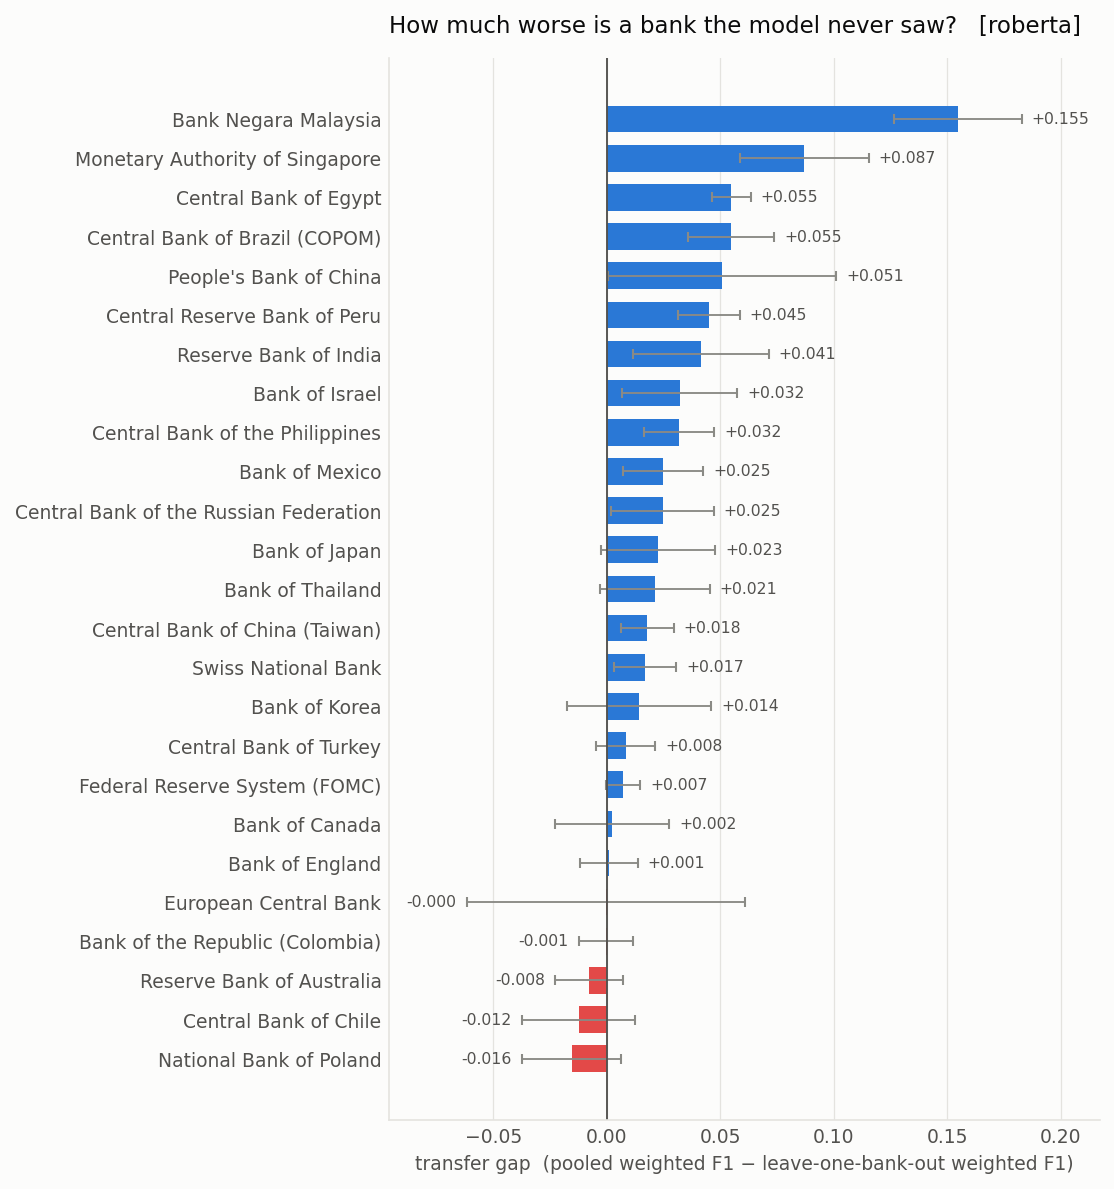

/content/drive/MyDrive/cs72_final_project/figures/roberta_fig2_gap_decomposition.png


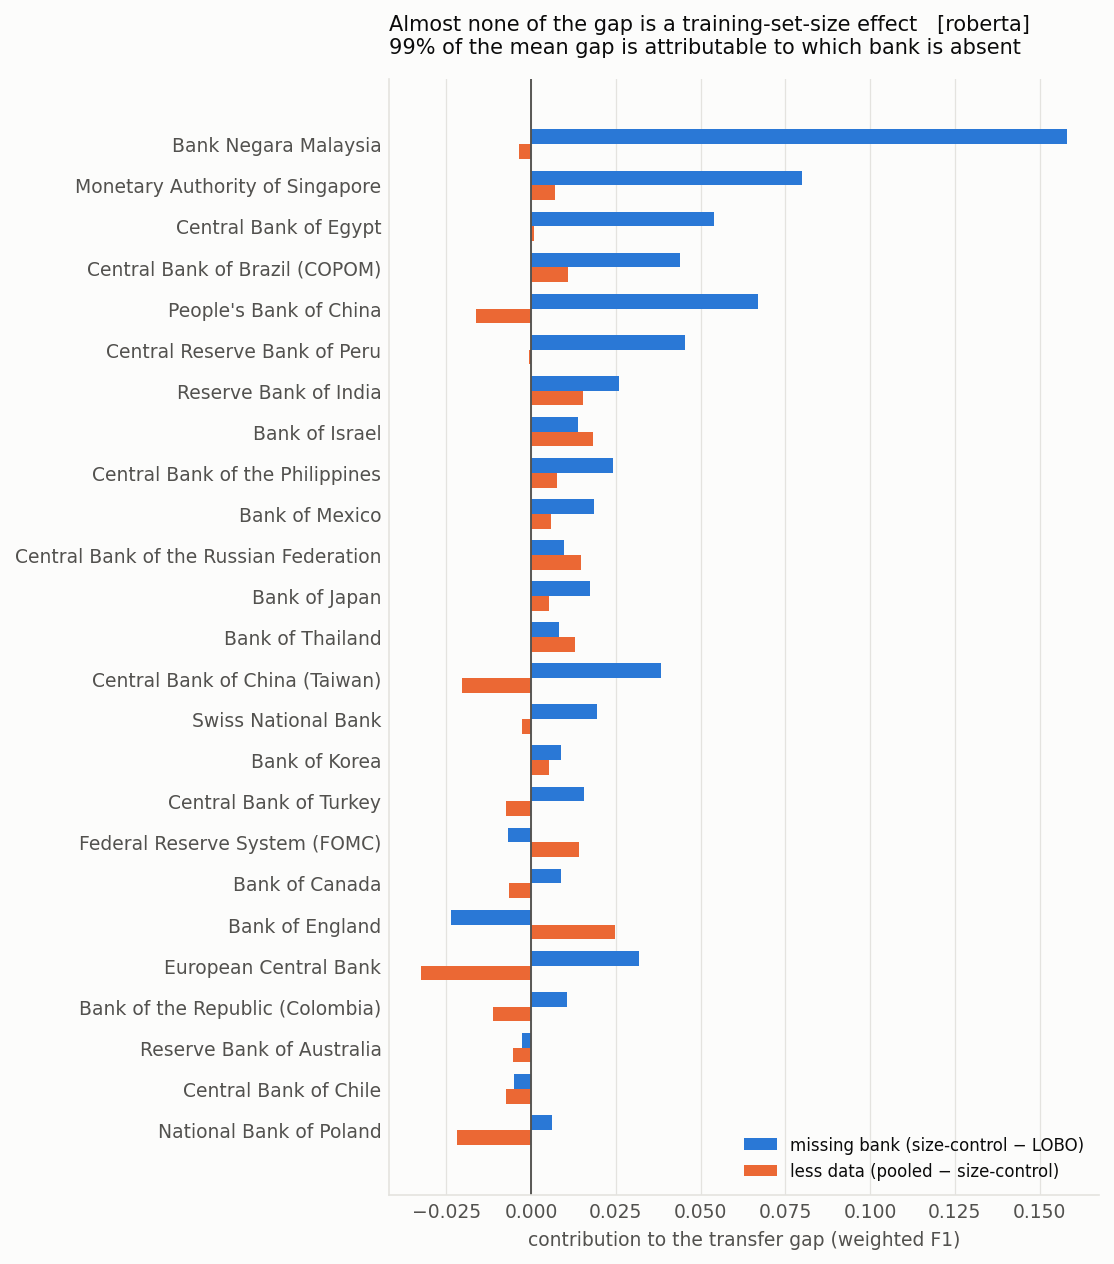

/content/drive/MyDrive/cs72_final_project/figures/roberta_fig3_features.png


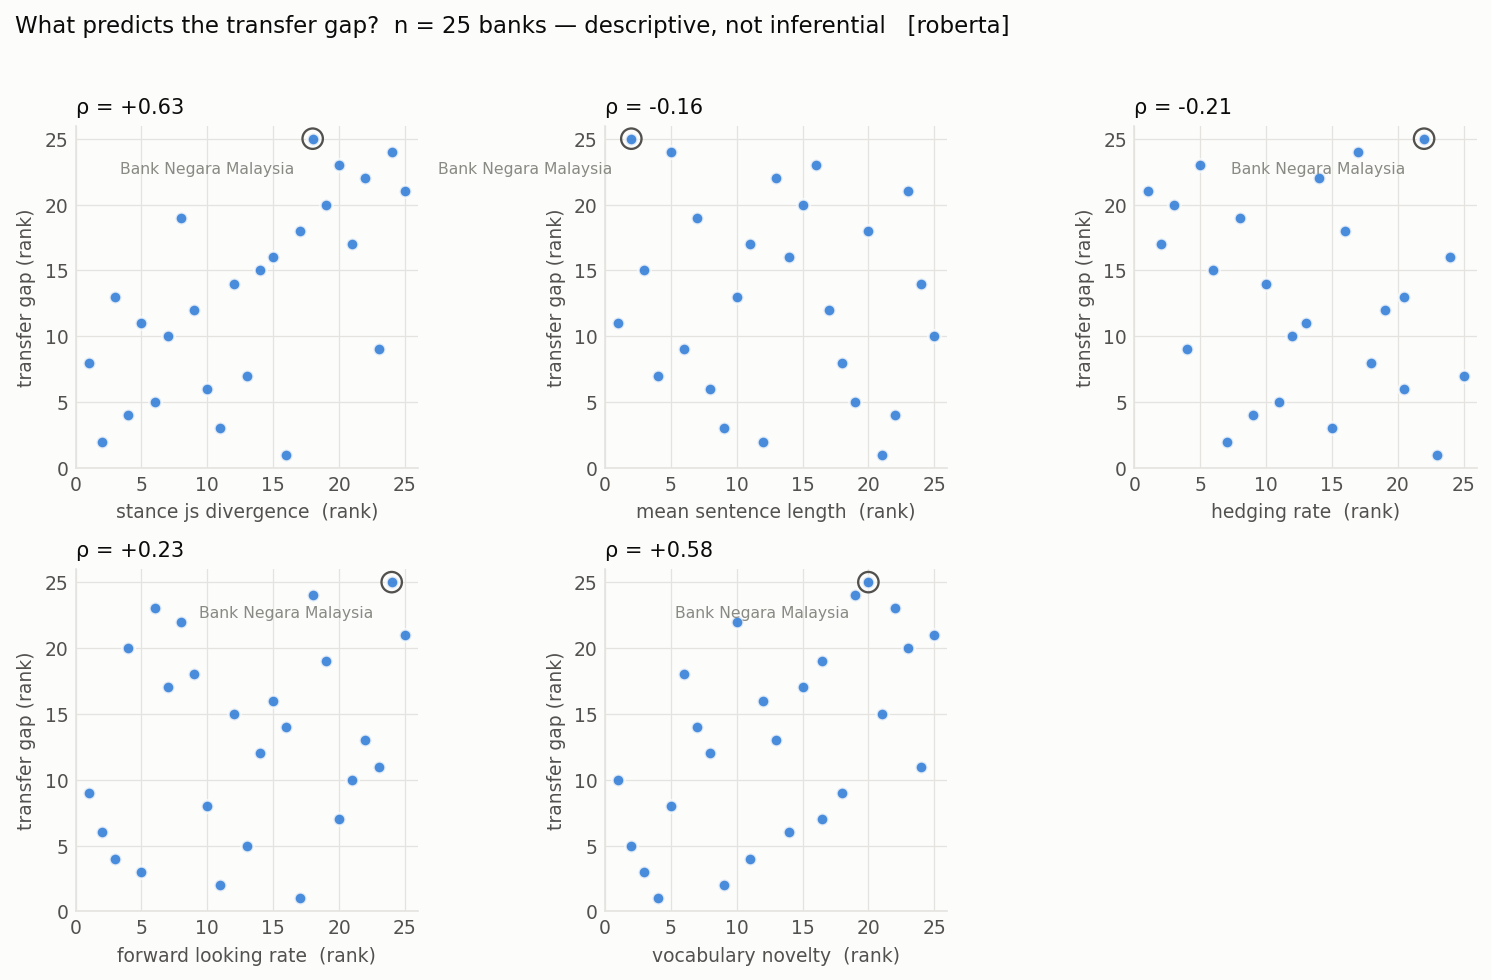

/content/drive/MyDrive/cs72_final_project/figures/roberta_fig4_per_class_f1.png


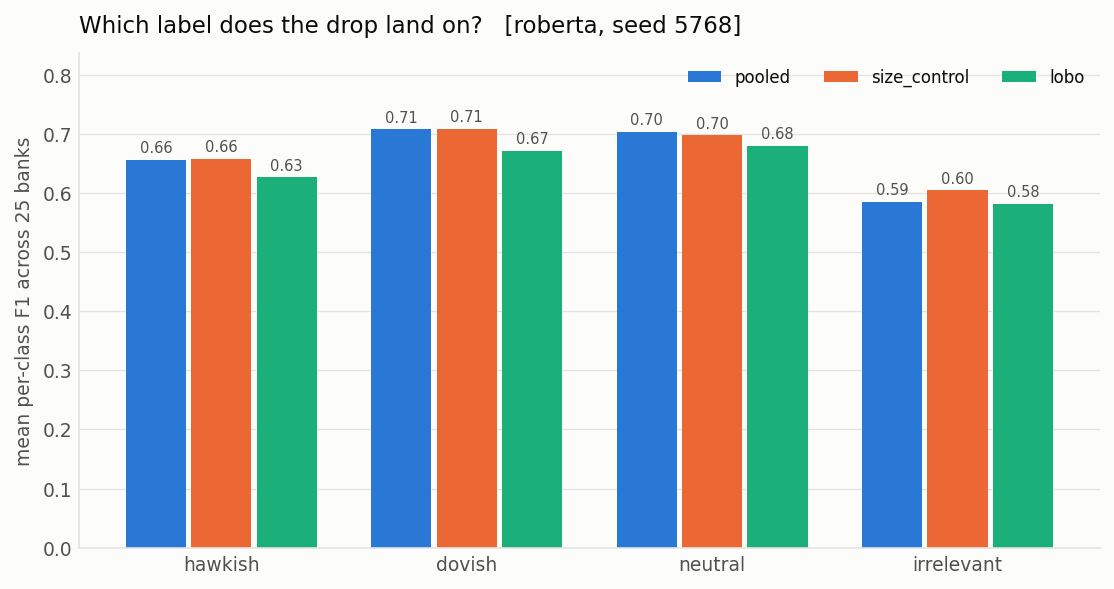

In [ ]:
from IPython.display import Image, display
for f in sorted(glob.glob(f"{C.FIGURES_DIR}/roberta_fig*.png")):
    print(f); display(Image(f))